# Adult Income: Supervised and Confidence-Based Pseudo-Labelling

## tl;dr

The reviewed run improves high-income recall from **53.07% to 55.78%** and F1 from **0.6076 to 0.6150**, while accuracy decreases from **83.40% to 83.08%**. The validation-selected threshold is 10, adding 4,742 pseudo-labelled observations. This is a small trade-off on a previously analysed coursework test set, not evidence of general superiority.

## Context & Methods

Compare mixed Gaussian/categorical Naive Bayes with one round of confidence-based pseudo-labelling. Select the absolute log-odds threshold from a fixed grid on a 20% stratified validation split (seed 42). Fit all transformations and the pseudo-label teacher on the training partition during selection. After selecting the threshold, refit on all labelled training data, regenerate pseudo-labels, and evaluate both final models on the supplied test.

### Key Assumptions

Use complete cases for labelled training and unlabelled data, matching the original selection policy. Retain all test rows, using training medians for missing continuous values and reserved unknown-category slots. Conditional independence and Gaussian continuous features remain modelling assumptions. The original test has been examined previously; this reviewed comparison is a retrospective benchmark.

## Data

Obtain `adult_supervised_train.csv`, `adult_unlabelled.csv` and `adult_test.csv` from the authorised original course distribution. Put them in `data/`, or set `ADULT_DATA_DIR`. Raw records and the optional unlabelled-with-labels file are not published or used. `results/run-record.json` identifies the reviewed inputs by SHA-256.

Install `requirements.txt` in the active Python environment. `MODEL_PYTHON` optionally selects a separate model runtime.

In [1]:
from pathlib import Path
import os, sys, json, subprocess
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
def display(frame):
    print(frame.to_string(index=False))
ROOT = Path.cwd() if (Path.cwd()/"src/adult_income.py").exists() else Path.cwd().parent
DATA = Path(os.environ.get("ADULT_DATA_DIR", str(ROOT/"data")))
MODEL_PYTHON = os.environ.get("MODEL_PYTHON", sys.executable)
command = [MODEL_PYTHON, "-B", "-X", "utf8", str(ROOT/"src/adult_income.py"), "--data-dir", str(DATA), "--output", str(ROOT/"results")]
completed = subprocess.run(command, cwd=ROOT, capture_output=True, text=True, encoding="utf-8")
if completed.returncode:
    raise RuntimeError("Model run failed. Check dependencies and the three required data files.\n" + completed.stderr)
print(completed.stdout)
record = json.loads((ROOT/"results/run-record.json").read_text())
assert all(record["checks"].values())
print("Training-partition, prior, missing-value and OOV checks passed.")

          model  accuracy  precision_positive  recall_positive  f1_positive  macro_f1  test_rows
     Supervised    0.8340              0.7107           0.5307       0.6076    0.7512      16281
Pseudo-labelled    0.8308              0.6851           0.5578       0.6150    0.7533      16281
Selected threshold: 10 | pseudo-label rows: 4742

Training-partition, prior, missing-value and OOV checks passed.


## Results

Positive-class metrics refer to `>50K`. Compare precision and recall together: the semi-supervised model recovers more high-income cases but also adds false positives.

          model  accuracy  precision_positive  recall_positive  f1_positive  macro_f1  test_rows
     Supervised    0.8340              0.7107           0.5307       0.6076    0.7512      16281
Pseudo-labelled    0.8308              0.6851           0.5578       0.6150    0.7533      16281


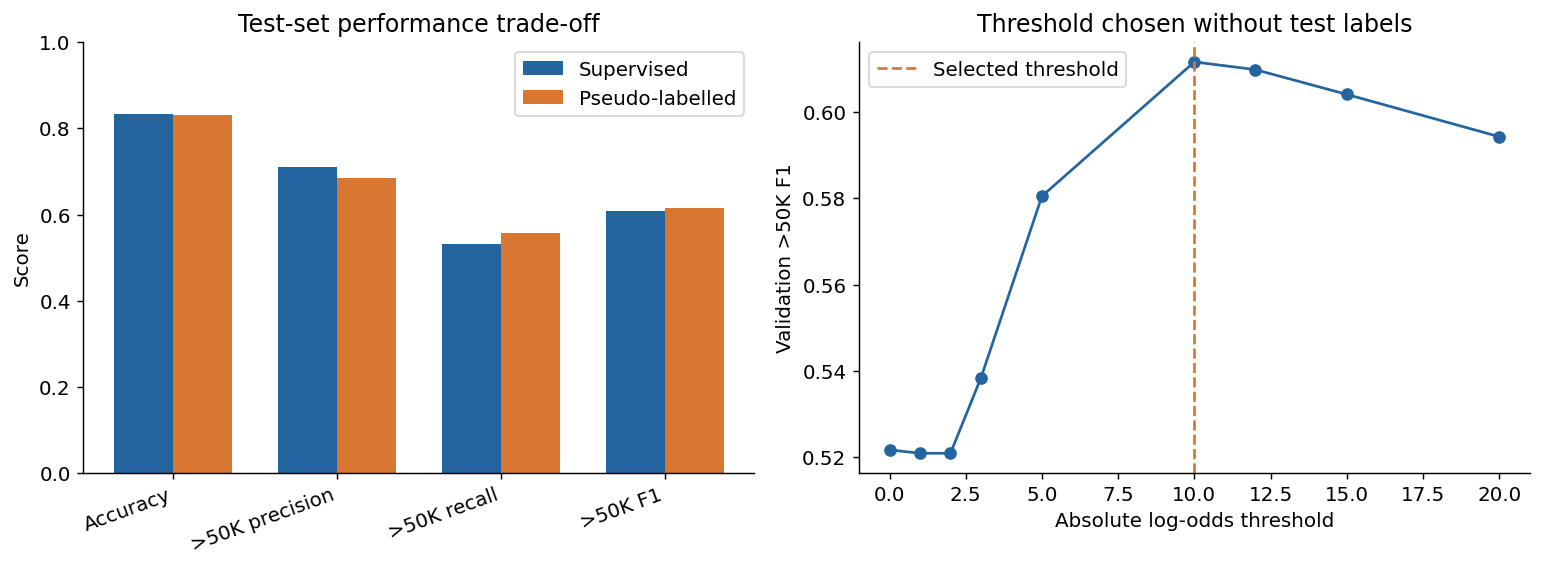

In [2]:
metrics = pd.read_csv(ROOT/"results/test-metrics.csv")
search = pd.read_csv(ROOT/"results/threshold-search.csv")
display(metrics.round(4))
plt.rcParams.update({"font.size":11, "axes.spines.top":False, "axes.spines.right":False})
fig, axes = plt.subplots(1,2,figsize=(12,4.5))
columns = ["accuracy", "precision_positive", "recall_positive", "f1_positive"]
labels = ["Accuracy", ">50K precision", ">50K recall", ">50K F1"]
x = np.arange(len(columns))
for i, row in metrics.iterrows():
    axes[0].bar(x+(i-.5)*.36, row[columns].to_numpy(dtype=float), .36, label=row["model"], color=["#2465A0","#D97732"][i])
axes[0].set_xticks(x,labels,rotation=20,ha="right")
axes[0].set_ylim(0,1);axes[0].set_ylabel("Score");axes[0].legend()
axes[0].set_title("Test-set performance trade-off")
axes[1].plot(search["threshold"],search["validation_f1_positive"],marker="o",color="#2465A0")
axes[1].axvline(record["selected_threshold"],color="#D97732",linestyle="--",label="Selected threshold")
axes[1].set_xlabel("Absolute log-odds threshold");axes[1].set_ylabel("Validation >50K F1")
axes[1].set_title("Threshold chosen without test labels");axes[1].legend()
fig.tight_layout();fig.savefig(ROOT/"results/performance-and-threshold.png",dpi=180,bbox_inches="tight")
plt.show()

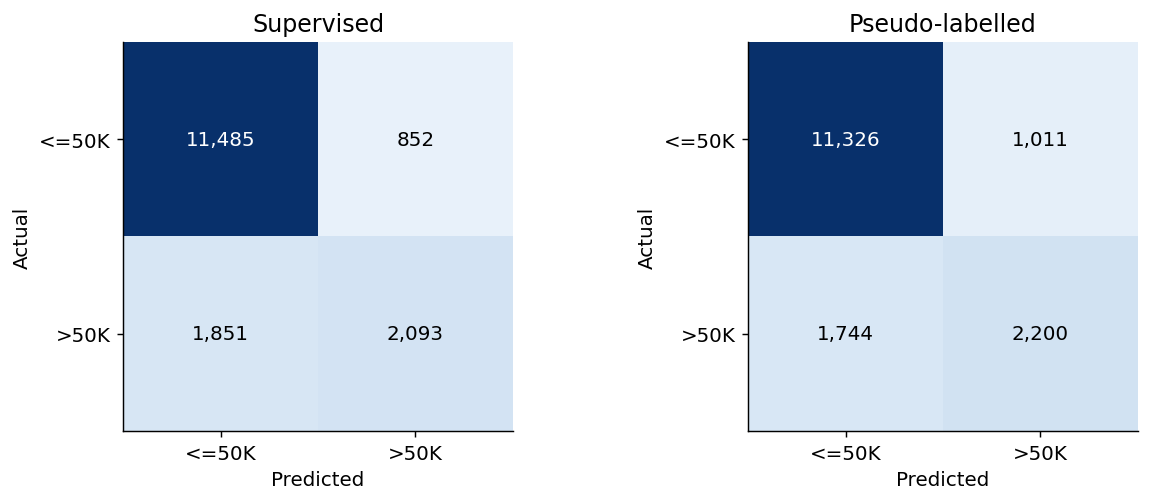

In [3]:
fig, axes = plt.subplots(1,2,figsize=(10,4))
for ax, name in zip(axes,["Supervised","Pseudo-labelled"]):
    cm = pd.read_csv(ROOT/"results"/(name.lower()+"-confusion.csv"),index_col=0).to_numpy()
    ax.imshow(cm,cmap="Blues",vmin=0,vmax=cm.max())
    for row in range(2):
        for col in range(2):
            ax.text(col,row,f"{cm[row,col]:,}",ha="center",va="center",color="white" if cm[row,col]>cm.max()/2 else "black")
    ax.set_xticks([0,1],["<=50K",">50K"]);ax.set_yticks([0,1],["<=50K",">50K"])
    ax.set_xlabel("Predicted");ax.set_ylabel("Actual");ax.set_title(name)
fig.tight_layout();fig.savefig(ROOT/"results/confusion-matrices.png",dpi=180,bbox_inches="tight")
plt.show()

## Takeaways

Confidence-based pseudo-labelling gives a modest positive-class recall/F1 gain in this run, accompanied by lower precision and accuracy. The revised results differ from the historical report after correcting teacher leakage, the doubled prior and train/test imputation handling. The notebook uses self-training-style pseudo-labels, not graph-based label propagation.

One split and a fixed threshold grid do not establish a statistically reliable improvement. Natural record duplicates, complete-case selection, sensitive demographic predictors and dataset age limit interpretation. No operational employment, credit or eligibility use is proposed. See `docs/REVIEW.md` for provenance and the distinction between original work and portfolio corrections.